<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/2_quantum/topics_in_qm/aqm_ch10_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Topics in Quantum Mechanics* — `aqm_ch10_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# AQM Chapter 10 — Figures
**Scattering Theory**

| Fig | Content |
|-----|---------|
| 10.1 | 1D scattering: incident, reflected, transmitted waves |
| 10.2 | 3D scattering geometry and differential cross-section |
| 10.3 | Argand diagram (unitarity circle) + phase shift $\delta_l$ vs $E$ at resonance |
| 10.4 | Born approximation: $d\sigma/d\Omega$ for Yukawa; form factor for uniform sphere |
| 10.5 | Rutherford $d\sigma/d\Omega$ vs $\theta$; Geiger–Marsden schematic |
| 10.6 | Bragg peaks + Debye–Waller suppression |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, Circle, FancyArrow
import os, zipfile

BG     = '#1e1e2e'
FG     = '#cdd6f4'
EDGE   = '#45475a'
BLUE   = '#7ec8e3'
YELLOW = '#f9c74f'
GREEN  = '#90ee90'
RED    = '#e07070'
PURPLE = '#c792ea'
ORANGE = '#ffb347'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.30,
    'font.family': 'DejaVu Sans', 'font.size': 13,
    'axes.titlesize': 14, 'axes.titleweight': 'bold',
    'axes.titlecolor': BLUE,
    'legend.framealpha': 0.3, 'legend.edgecolor': EDGE,
})

OUTDIR = 'figures/ch10'
os.makedirs(OUTDIR, exist_ok=True)

def save(name):
    plt.savefig(f'{OUTDIR}/{name}', dpi=180, bbox_inches='tight', facecolor=BG)
    plt.show()
    print(f'  saved -> {OUTDIR}/{name}')

print('Setup complete.')

Setup complete.


## Figure 10.1 — 1D Scattering
**Physics**: incident wave $e^{ikx}$, reflected $r e^{-ikx}$, transmitted $t e^{ikx}$; $R+T=1$.
Lower panel: transmission $T(E)$ through a square barrier showing tunnelling below barrier and resonances above.

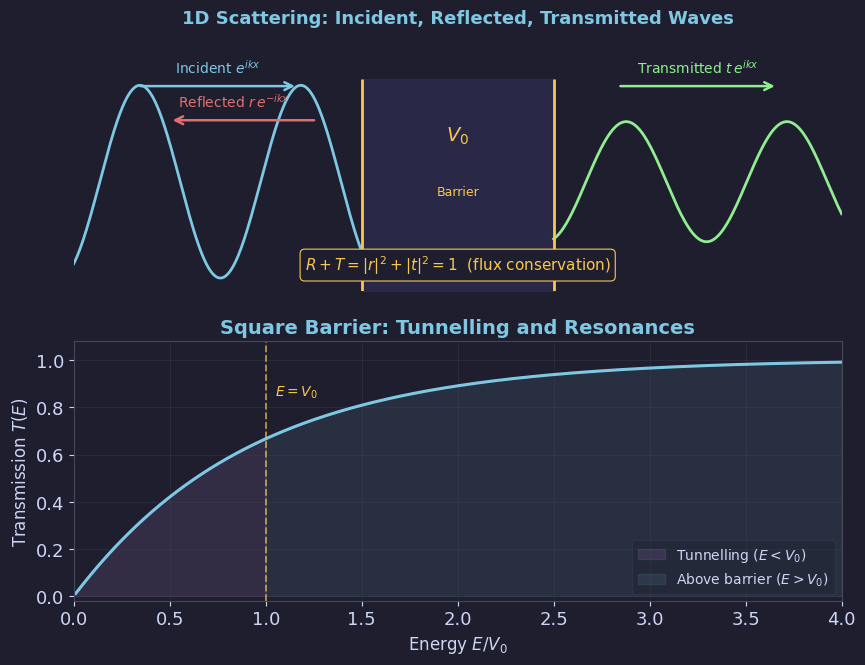

  saved -> figures/ch10/fig01_1d_scattering.png


In [2]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7))
fig.patch.set_facecolor(BG)

# ── Upper: schematic wave diagram ────────────────────────────
ax1.set_facecolor(BG)
ax1.set_xlim(-6, 6)
ax1.set_ylim(-1.6, 2.2)
ax1.axis('off')

x_left  = np.linspace(-6, -1.5, 300)
x_right = np.linspace( 1.5,  6, 300)
k = 2.5

# Incident + reflected (left region)
r_amp = 0.45
psi_left = np.cos(k * x_left) + r_amp * np.cos(-k * x_left + 0.5)
ax1.plot(x_left, psi_left, color=BLUE, lw=2.0)

# Transmitted (right region)
t_amp = 0.88
psi_right = t_amp * np.cos(k * x_right - 0.3)
ax1.plot(x_right, psi_right, color=GREEN, lw=2.0)

# Potential barrier
ax1.fill_between([-1.5, 1.5], [-1.6, -1.6], [1.5, 1.5],
                 color='#2d2d4e', alpha=0.8)
ax1.vlines([-1.5, 1.5], -1.6, 1.5, colors=YELLOW, lw=2.0)
ax1.text(0, 0.6, r'$V_0$', color=YELLOW, ha='center', fontsize=14,
         fontweight='bold')
ax1.text(0, -0.2, 'Barrier', color=YELLOW, ha='center', fontsize=9)

# Labels and arrows
ax1.annotate('', xy=(-2.5, 1.4), xytext=(-5.0, 1.4),
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=1.8,
                             mutation_scale=14))
ax1.text(-3.75, 1.6, r'Incident $e^{ikx}$', color=BLUE, ha='center', fontsize=10)

ax1.annotate('', xy=(-4.5, 0.9), xytext=(-2.2, 0.9),
             arrowprops=dict(arrowstyle='->', color=RED, lw=1.8,
                             mutation_scale=14))
ax1.text(-3.5, 1.1, r'Reflected $r\,e^{-ikx}$', color=RED, ha='center', fontsize=10)

ax1.annotate('', xy=(5.0, 1.4), xytext=(2.5, 1.4),
             arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.8,
                             mutation_scale=14))
ax1.text(3.75, 1.6, r'Transmitted $t\,e^{ikx}$', color=GREEN, ha='center', fontsize=10)

# R+T=1 annotation
ax1.text(0, -1.3,
         r'$R + T = |r|^2 + |t|^2 = 1$  (flux conservation)',
         color=YELLOW, ha='center', fontsize=11,
         bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=YELLOW, lw=0.8))

ax1.set_title('1D Scattering: Incident, Reflected, Transmitted Waves',
              color=BLUE, fontsize=13)

# ── Lower: T(E) for square barrier ───────────────────────────
ax2.set_facecolor(BG)
V0 = 1.0   # barrier height (units: V0=1)
a  = 1.0   # barrier half-width
E  = np.linspace(0.01, 4.0, 2000)

T_vals = np.zeros_like(E)
for i, Ei in enumerate(E):
    if Ei < V0:
        # Tunnelling regime
        kappa = np.sqrt(2 * (V0 - Ei))  # in units where 2m/hbar^2=2
        sh = np.sinh(kappa * a)
        T_vals[i] = 1 / (1 + (V0**2 * sh**2) / (4 * Ei * (V0 - Ei)))
    else:
        # Oscillatory regime
        k2 = np.sqrt(2 * (Ei - V0))
        si = np.sin(k2 * a)
        T_vals[i] = 1 / (1 + (V0**2 * si**2) / (4 * Ei * (Ei - V0)))

ax2.plot(E, T_vals, color=BLUE, lw=2.2)
ax2.axvline(V0, color=YELLOW, lw=1.3, ls='--', alpha=0.7)
ax2.text(V0 + 0.05, 0.85, r'$E = V_0$', color=YELLOW, fontsize=10)

# Mark resonance peaks (T=1)
resonance_mask = (E > V0) & (T_vals > 0.995)
res_E = E[resonance_mask]
if len(res_E) > 0:
    # Find distinct resonance positions
    gaps = np.where(np.diff(res_E) > 0.1)[0]
    res_positions = [res_E[0]]
    for g in gaps:
        res_positions.append(res_E[g+1])
    for rp in res_positions[:4]:
        ax2.plot(rp, 1.0, '*', color=RED, ms=10, zorder=5)
    ax2.text(res_positions[0]+0.1, 0.96, 'Resonances\n($T=1$)',
             color=RED, fontsize=9)

ax2.fill_between(E, 0, T_vals, where=E<V0, color=PURPLE, alpha=0.12,
                 label='Tunnelling ($E<V_0$)')
ax2.fill_between(E, 0, T_vals, where=E>V0, color=BLUE, alpha=0.10,
                 label='Above barrier ($E>V_0$)')

ax2.set_xlabel(r'Energy $E / V_0$', fontsize=12)
ax2.set_ylabel(r'Transmission $T(E)$', fontsize=12)
ax2.set_title('Square Barrier: Tunnelling and Resonances', color=BLUE)
ax2.set_xlim(0, 4)
ax2.set_ylim(-0.02, 1.08)
ax2.legend(fontsize=10, labelcolor=FG)
ax2.grid(True)

plt.tight_layout(pad=1.5)
save('fig01_1d_scattering.png')

## Figure 10.2 — 3D Scattering Geometry
**Physics**: incident plane wave, scattered spherical wave; detector at $\theta$;
$d\sigma/d\Omega = |f(\theta)|^2$.

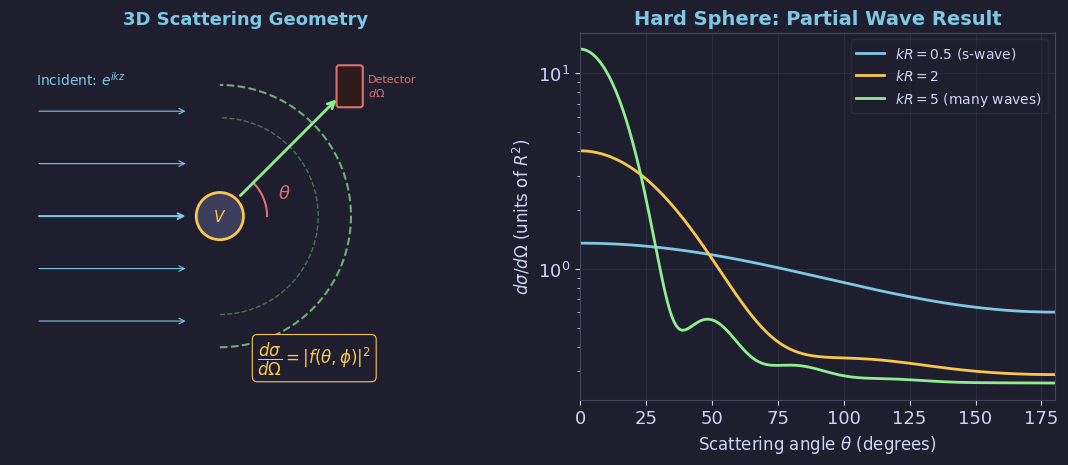

  saved -> figures/ch10/fig02_3d_scattering.png


In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))
fig.patch.set_facecolor(BG)

# ── Left: geometry schematic ──────────────────────────────────
ax1.set_facecolor(BG)
ax1.set_xlim(-4, 5)
ax1.set_ylim(-3.5, 3.5)
ax1.set_aspect('equal')
ax1.axis('off')

# Incident beam (parallel rays)
for y0 in [-2.0, -1.0, 0.0, 1.0, 2.0]:
    ax1.annotate('', xy=(-0.6, y0), xytext=(-3.5, y0),
                 arrowprops=dict(arrowstyle='->', color=BLUE,
                                 lw=1.5 if y0==0 else 0.8,
                                 mutation_scale=10))
ax1.text(-3.5, 2.5, r'Incident: $e^{ikz}$', color=BLUE, fontsize=10)

# Scatterer
scatter_circ = Circle((0, 0), 0.45, facecolor='#3d3d5c',
                       edgecolor=YELLOW, lw=2, zorder=5)
ax1.add_patch(scatter_circ)
ax1.text(0, 0, r'$V$', color=YELLOW, ha='center', va='center',
         fontsize=11, zorder=6)

# Scattered wave (arc)
theta_arc = np.linspace(-np.pi/2, np.pi/2, 200)
R_arc = 2.5
ax1.plot(R_arc*np.cos(theta_arc), R_arc*np.sin(theta_arc),
         color=GREEN, lw=1.5, ls='--', alpha=0.7)
ax1.plot(R_arc*np.cos(theta_arc)*0.75, R_arc*np.sin(theta_arc)*0.75,
         color=GREEN, lw=1.0, ls='--', alpha=0.4)

# Scattered ray at angle θ
theta_det = np.pi / 4
ax1.annotate('', xy=(3.2*np.cos(theta_det), 3.2*np.sin(theta_det)),
             xytext=(0.5*np.cos(theta_det), 0.5*np.sin(theta_det)),
             arrowprops=dict(arrowstyle='->', color=GREEN,
                             lw=2.0, mutation_scale=12))

# Angle arc
theta_ang = np.linspace(0, theta_det, 60)
ax1.plot(0.9*np.cos(theta_ang), 0.9*np.sin(theta_ang),
         color=RED, lw=1.5)
ax1.text(1.1, 0.35, r'$\theta$', color=RED, fontsize=13)

# Detector
det_x = 3.5*np.cos(theta_det)
det_y = 3.5*np.sin(theta_det)
det_box = mpatches.FancyBboxPatch((det_x-0.2, det_y-0.35), 0.4, 0.7,
    boxstyle='round,pad=0.05', edgecolor=RED, facecolor='#2d1a1a', lw=1.5)
ax1.add_patch(det_box)
ax1.text(det_x+0.35, det_y, 'Detector\n' + r'$d\Omega$',
         color=RED, fontsize=8, va='center')

# dσ/dΩ label
ax1.text(1.8, -2.8,
         r'$\dfrac{d\sigma}{d\Omega} = |f(\theta,\phi)|^2$',
         color=YELLOW, fontsize=12, ha='center',
         bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=YELLOW, lw=0.8))

ax1.set_title('3D Scattering Geometry', color=BLUE, fontsize=13)

# ── Right: dσ/dΩ for hard sphere (partial waves, numeric) ─────
ax2.set_facecolor(BG)

def hard_sphere_dsigma(theta, kR, l_max=20):
    """Hard sphere dσ/dΩ using partial wave expansion."""
    from scipy.special import spherical_jn, spherical_yn
    cos_t = np.cos(theta)
    f = 0j
    for l in range(l_max+1):
        jl  = spherical_jn(l, kR)
        jl_ = spherical_jn(l, kR, derivative=True)
        nl  = spherical_yn(l, kR)
        nl_ = spherical_yn(l, kR, derivative=True)
        # tan(delta_l) = jl(kR)/nl(kR)
        tan_delta = -jl / nl
        delta_l = np.arctan(tan_delta)
        fl = np.exp(1j*delta_l) * np.sin(delta_l) / kR
        # Legendre polynomial
        from scipy.special import legendre
        Pl = legendre(l)(cos_t)
        f += (2*l + 1) * fl * Pl
    return np.abs(f)**2

theta = np.linspace(0.01, np.pi, 300)
theta_deg = np.degrees(theta)

for kR, color, label in [(0.5, BLUE, '$kR=0.5$ (s-wave)'),
                          (2.0, YELLOW, '$kR=2$'),
                          (5.0, GREEN, '$kR=5$ (many waves)')]:
    ds = hard_sphere_dsigma(theta, kR, l_max=int(kR)+8)
    ax2.plot(theta_deg, ds, color=color, lw=2.0, label=label)

ax2.set_xlabel(r'Scattering angle $\theta$ (degrees)', fontsize=12)
ax2.set_ylabel(r'$d\sigma/d\Omega$ (units of $R^2$)', fontsize=12)
ax2.set_title('Hard Sphere: Partial Wave Result', color=BLUE)
ax2.legend(fontsize=10, labelcolor=FG)
ax2.set_xlim(0, 180)
ax2.set_yscale('log')
ax2.grid(True)

plt.tight_layout(pad=1.5)
save('fig02_3d_scattering.png')

## Figure 10.3 — Argand Diagram + Phase Shift at Resonance
**Physics**: $f_l = e^{i\delta_l}\sin\delta_l/k$ traces a unit circle (Argand);
at resonance $\delta_l$ passes through $\pi/2$ and $\sigma_l$ peaks.

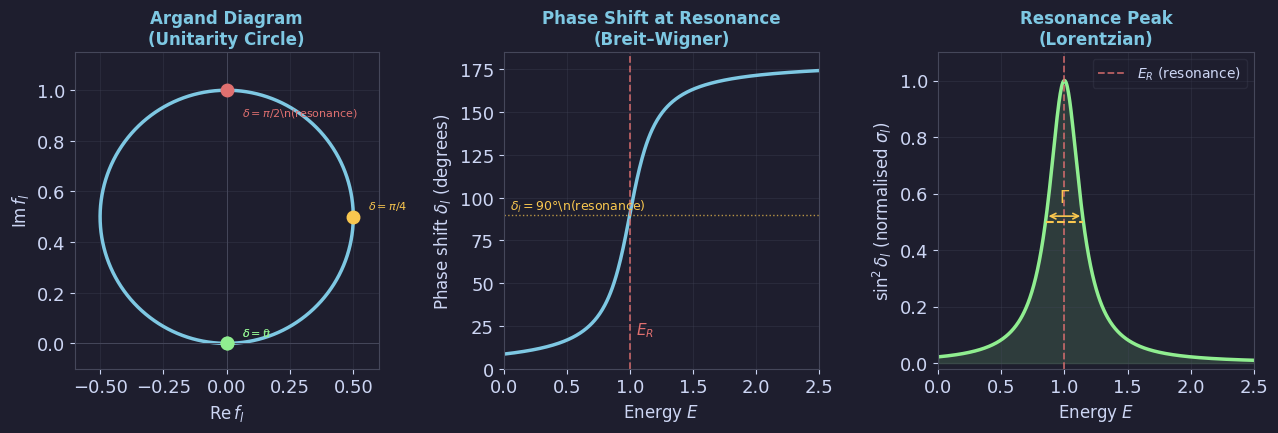

  saved -> figures/ch10/fig03_argand_phase_shift.png


In [4]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 4.5))
fig.patch.set_facecolor(BG)

# ── Left: Argand diagram ──────────────────────────────────────
ax1.set_facecolor(BG)
ax1.set_aspect('equal')

# Unitarity circle: center (0, 1/(2k)), radius 1/(2k); set k=1
k = 1.0
delta_vals = np.linspace(0, np.pi, 300)
fl_re = np.cos(delta_vals) * np.sin(delta_vals) / k   # Re f_l
fl_im = np.sin(delta_vals)**2 / k                      # Im f_l

ax1.plot(fl_re, fl_im, color=BLUE, lw=2.5)
ax1.plot(0, 0, 'o', color=FG, ms=7, zorder=5)
ax1.plot(0, 1/k, 'o', color=YELLOW, ms=7, zorder=5, label='Centre')

# Mark key points
for delta, label, color in [(0, r'$\delta=0$', GREEN),
                              (np.pi/4, r'$\delta=\pi/4$', YELLOW),
                              (np.pi/2, r'$\delta=\pi/2$\n(resonance)', RED),
                              (np.pi, r'$\delta=\pi$', GREEN)]:
    x = np.cos(delta)*np.sin(delta)/k
    y = np.sin(delta)**2/k
    ax1.plot(x, y, 'o', color=color, ms=9, zorder=6)
    offset = (0.06, 0.03)
    if delta == np.pi/2:
        offset = (0.06, -0.1)
    ax1.text(x + offset[0], y + offset[1], label,
             color=color, fontsize=8)

# Optical theorem: Im f(0) = σ/(4π/k)
ax1.axhline(0, color=EDGE, lw=0.7)
ax1.axvline(0, color=EDGE, lw=0.7)
ax1.set_xlabel(r'$\mathrm{Re}\,f_l$', fontsize=12)
ax1.set_ylabel(r'$\mathrm{Im}\,f_l$', fontsize=12)
ax1.set_title('Argand Diagram\n(Unitarity Circle)', color=BLUE, fontsize=12)
ax1.grid(True)
ax1.set_xlim(-0.6, 0.6)
ax1.set_ylim(-0.1, 1.15)

# ── Middle: phase shift δ_l vs E (Breit–Wigner) ──────────────
ax2.set_facecolor(BG)
E_res, Gamma_BW = 1.0, 0.3
E = np.linspace(0, 2.5, 500)
# Breit–Wigner: tan δ = (Γ/2)/(E_res - E)
delta_BW = np.arctan2(Gamma_BW/2, E_res - E) + np.pi * (E > E_res)
# Smooth version
delta_BW = np.arctan((Gamma_BW/2) / (E_res - E + 1e-10))
delta_BW[E > E_res] += np.pi

ax2.plot(E, np.degrees(delta_BW), color=BLUE, lw=2.5)
ax2.axvline(E_res, color=RED, lw=1.3, ls='--', alpha=0.8)
ax2.axhline(90, color=YELLOW, lw=1.0, ls=':', alpha=0.7)
ax2.text(E_res+0.05, 20, r'$E_R$', color=RED, fontsize=11)
ax2.text(0.05, 93, r'$\delta_l=90°$\n(resonance)', color=YELLOW, fontsize=9)

ax2.set_xlabel(r'Energy $E$', fontsize=12)
ax2.set_ylabel(r'Phase shift $\delta_l$ (degrees)', fontsize=12)
ax2.set_title('Phase Shift at Resonance\n(Breit–Wigner)', color=BLUE, fontsize=12)
ax2.set_xlim(0, 2.5)
ax2.set_ylim(0, 185)
ax2.grid(True)

# ── Right: σ_l vs E (resonance peak) ─────────────────────────
ax3.set_facecolor(BG)
# sigma_l = (4*np.pi / E) * np.sin(delta_BW)**2  # in units where k²=E (2m/hbar²=2)
# Normalise to show shape
sigma_l = np.sin(delta_BW)**2
ax3.plot(E, sigma_l, color=GREEN, lw=2.5)
ax3.fill_between(E, 0, sigma_l, color=GREEN, alpha=0.15)
ax3.axvline(E_res, color=RED, lw=1.3, ls='--', alpha=0.8,
            label=r'$E_R$ (resonance)')

# Γ annotation
half_idx = np.where(sigma_l >= 0.5)[0]
if len(half_idx) > 1:
    E_half_lo = E[half_idx[0]]
    E_half_hi = E[half_idx[-1]]
    ax3.hlines(0.5, E_half_lo, E_half_hi, colors=YELLOW, lw=1.5, ls='--')
    ax3.annotate('', xy=(E_half_hi, 0.52), xytext=(E_half_lo, 0.52),
                 arrowprops=dict(arrowstyle='<->', color=YELLOW,
                                 lw=1.2, mutation_scale=10))
    ax3.text((E_half_lo+E_half_hi)/2, 0.57,
             r'$\Gamma$', color=YELLOW, ha='center', fontsize=12)

ax3.set_xlabel(r'Energy $E$', fontsize=12)
ax3.set_ylabel(r'$\sin^2\delta_l$ (normalised $\sigma_l$)', fontsize=12)
ax3.set_title('Resonance Peak\n(Lorentzian)', color=BLUE, fontsize=12)
ax3.set_xlim(0, 2.5)
ax3.set_ylim(-0.02, 1.1)
ax3.legend(fontsize=10, labelcolor=FG)
ax3.grid(True)

plt.tight_layout(pad=1.0)
save('fig03_argand_phase_shift.png')

## Figure 10.4 — Born Approximation: Yukawa and Form Factor
**Physics**: $d\sigma/d\Omega \propto 1/(q^2+\mu^2)^2$ for Yukawa;
form factor $|F(q)|^2$ for uniform sphere of radius $R$.

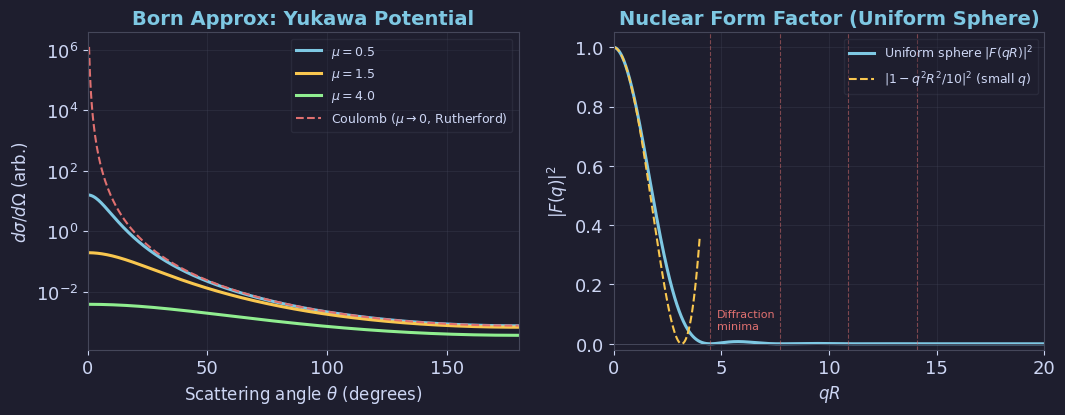

  saved -> figures/ch10/fig04_born_yukawa_formfactor.png


In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
fig.patch.set_facecolor(BG)

# ── Left: Born dσ/dΩ for Yukawa at several μ ─────────────────
k = 3.0     # incident wavevector
theta = np.linspace(0.01, np.pi, 500)
q = 2 * k * np.sin(theta / 2)   # momentum transfer

for mu, color, label in [(0.5, BLUE,   r'$\mu=0.5$'),
                          (1.5, YELLOW, r'$\mu=1.5$'),
                          (4.0, GREEN,  r'$\mu=4.0$')]:
    dsigma = 1.0 / (q**2 + mu**2)**2   # A=1, prefactors absorbed
    ax1.semilogy(np.degrees(theta), dsigma,
                 color=color, lw=2.2, label=label)

# Coulomb limit (μ→0): ~1/sin^4(θ/2)
dsigma_coul = 1.0 / (4 * k**2 * np.sin(theta/2)**2)**2
ax1.semilogy(np.degrees(theta), dsigma_coul,
             color=RED, lw=1.5, ls='--',
             label=r'Coulomb ($\mu\to 0$, Rutherford)')

ax1.set_xlabel(r'Scattering angle $\theta$ (degrees)', fontsize=12)
ax1.set_ylabel(r'$d\sigma/d\Omega$ (arb.)', fontsize=12)
ax1.set_title('Born Approx: Yukawa Potential', color=BLUE)
ax1.legend(fontsize=9, labelcolor=FG)
ax1.set_xlim(0, 180)
ax1.grid(True)

# ── Right: nuclear form factor for uniform sphere ─────────────
R_fm = 1.0   # nuclear radius (in units, e.g. fm)
q_vals = np.linspace(0.001, 20, 1000)   # q*R dimensionless

# Form factor for uniform sphere: F(q) = 3[sin(qR)-qR cos(qR)]/(qR)^3
def form_factor_sphere(qR):
    return 3 * (np.sin(qR) - qR * np.cos(qR)) / qR**3

F_sphere = form_factor_sphere(q_vals)

ax2.plot(q_vals, F_sphere**2, color=BLUE, lw=2.2,
         label=r'Uniform sphere $|F(qR)|^2$')
ax2.axhline(0, color=EDGE, lw=0.7)

# Diffraction minima
zeros = [4.493, 7.725, 10.90, 14.07]  # zeros of form factor
for z in zeros:
    if z < 20:
        ax2.axvline(z, color=RED, lw=0.8, ls='--', alpha=0.5)
ax2.text(4.8, 0.05, 'Diffraction\nminima', color=RED, fontsize=8)

# Small-q expansion: F ≈ 1 - q²R²/10
q_small = np.linspace(0, 4, 100)
F_expand = (1 - q_small**2 / 10)**2
ax2.plot(q_small, F_expand, color=YELLOW, lw=1.5, ls='--',
         label=r'$|1 - q^2R^2/10|^2$ (small $q$)')

ax2.set_xlabel(r'$qR$', fontsize=12)
ax2.set_ylabel(r'$|F(q)|^2$', fontsize=12)
ax2.set_title('Nuclear Form Factor (Uniform Sphere)', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG)
ax2.set_xlim(0, 20)
ax2.set_ylim(-0.02, 1.05)
ax2.grid(True)

plt.tight_layout(pad=1.5)
save('fig04_born_yukawa_formfactor.png')

## Figure 10.5 — Rutherford Scattering
**Physics**: $d\sigma/d\Omega = (a/4)^2 \sin^{-4}(\theta/2)$ where $a = ZZ'e^2/E$;
diverges as $\theta\to 0$.

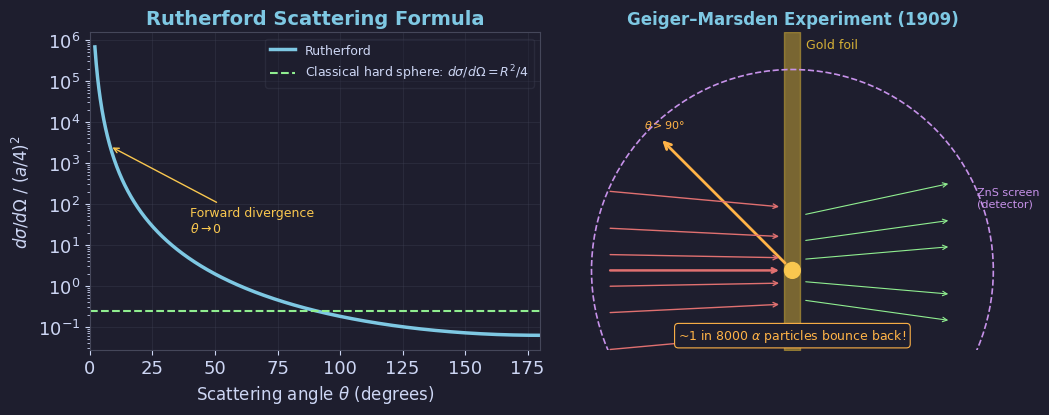

  saved -> figures/ch10/fig05_rutherford.png


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
fig.patch.set_facecolor(BG)

# ── Left: Rutherford dσ/dΩ vs θ ───────────────────────────────
theta = np.linspace(2, 180, 1000)   # degrees, avoid θ=0
theta_r = np.radians(theta)

# Rutherford: dσ/dΩ = (a/4)^2 / sin^4(θ/2), set a=1
dsigma_R = 1.0 / (4 * np.sin(theta_r/2)**2)**2

ax1.semilogy(theta, dsigma_R, color=BLUE, lw=2.5,
             label='Rutherford')

# Classical hard sphere for comparison
ax1.axhline(0.25, color=GREEN, lw=1.5, ls='--',
            label=r'Classical hard sphere: $d\sigma/d\Omega = R^2/4$')

# Forward divergence annotation
ax1.annotate('Forward divergence\n' + r'$\theta\to 0$',
             xy=(8, dsigma_R[np.argmin(np.abs(theta-8))]),
             xytext=(40, 20),
             color=YELLOW, fontsize=9,
             arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.0))

ax1.set_xlabel(r'Scattering angle $\theta$ (degrees)', fontsize=12)
ax1.set_ylabel(r'$d\sigma/d\Omega$ / $(a/4)^2$', fontsize=12)
ax1.set_title('Rutherford Scattering Formula', color=BLUE)
ax1.legend(fontsize=9, labelcolor=FG)
ax1.set_xlim(0, 180)
ax1.grid(True)

# ── Right: Geiger–Marsden schematic ──────────────────────────
ax2.set_facecolor(BG)
ax2.set_xlim(-4, 4)
ax2.set_ylim(-1.5, 4.5)
ax2.set_aspect('equal')
ax2.axis('off')

# Gold foil
ax2.fill_between([-0.15, 0.15], [-1.5, -1.5], [4.5, 4.5],
                 color='#d4af37', alpha=0.5)
ax2.text(0.25, 4.2, 'Gold foil', color='#d4af37', fontsize=9)

# Nucleus at centre
nuc = Circle((0, 0), 0.15, color=YELLOW, zorder=5)
ax2.add_patch(nuc)

# Incident alpha particles
impact_params = [-1.5, -0.8, -0.3, 0.0, 0.3, 0.8, 1.5]
for b in impact_params:
    # Rough classical trajectory
    theta_c = 2 * np.arctan(1.0 / (2 * abs(b) + 0.01)) * np.sign(b) if b != 0 else np.pi
    # Incoming
    ax2.annotate('', xy=(-0.2, b * 0.8), xytext=(-3.5, b),
                 arrowprops=dict(arrowstyle='->', color=RED,
                                 lw=1.0 if abs(b) > 0.2 else 1.8,
                                 mutation_scale=8))
    # Outgoing (deflected)
    if abs(b) < 0.15:
        # Large angle scatter
        ax2.annotate('', xy=(-2.5, 2.5), xytext=(-0.1, 0.1),
                     arrowprops=dict(arrowstyle='->', color=ORANGE,
                                     lw=2.0, mutation_scale=12))
        ax2.text(-2.8, 2.7, r'$\theta > 90°$', color=ORANGE, fontsize=8)
    else:
        x_out = 3.0
        y_out = b + 0.15 * np.sign(b)
        ax2.annotate('', xy=(x_out, y_out), xytext=(0.2, b*0.7),
                     arrowprops=dict(arrowstyle='->', color=GREEN,
                                     lw=0.8, mutation_scale=8))

# Detector (circular)
det = Circle((0, 0), 3.8, fill=False, edgecolor=PURPLE, lw=1.2, ls='--')
ax2.add_patch(det)
ax2.text(3.5, 1.2, 'ZnS screen\n(detector)', color=PURPLE, fontsize=8)

ax2.set_title('Geiger–Marsden Experiment (1909)', color=BLUE, fontsize=12)
ax2.text(0, -1.3, r'~1 in 8000 $\alpha$ particles bounce back!',
         color=ORANGE, ha='center', fontsize=9,
         bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=ORANGE, lw=0.8))

plt.tight_layout(pad=1.5)
save('fig05_rutherford.png')

## Figure 10.6 — Bragg Peaks and Debye–Waller Factor
**Physics**: $d\sigma/d\Omega \propto |S(\mathbf{q})|^2$; peaks at $\mathbf{q}=\mathbf{G}$;
Debye–Waller suppresses peaks by $e^{-q^2\langle u^2\rangle}$ at finite $T$.

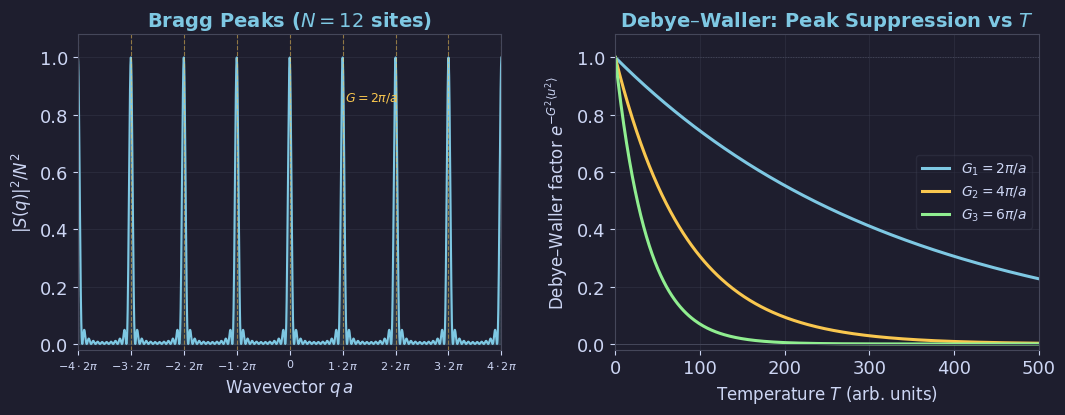

  saved -> figures/ch10/fig06_bragg_debye_waller.png


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
fig.patch.set_facecolor(BG)

# ── Left: 1D Bragg diffraction pattern ───────────────────────
N   = 12    # number of lattice sites
a   = 1.0   # lattice constant
q   = np.linspace(-8*np.pi, 8*np.pi, 4000)  # wavevector in units of 1/a

# Structure factor: S(q) = sum_{n=0}^{N-1} e^{iqna}
# |S(q)|^2 = sin^2(Nqa/2) / sin^2(qa/2)
qa2 = q * a / 2
with np.errstate(divide='ignore', invalid='ignore'):
    S2 = np.where(np.abs(np.sin(qa2)) < 1e-8,
                  float(N)**2,
                  np.sin(N*qa2)**2 / np.sin(qa2)**2)
S2_norm = S2 / N**2

ax1.plot(q, S2_norm, color=BLUE, lw=1.5)
ax1.fill_between(q, 0, S2_norm, color=BLUE, alpha=0.15)

# Mark Bragg peaks at q = 2πn/a
G_vals = np.arange(-4, 5) * 2 * np.pi
for G in G_vals:
    ax1.axvline(G, color=YELLOW, lw=0.8, ls='--', alpha=0.5)
ax1.text(2*np.pi + 0.3, 0.85, r'$G = 2\pi/a$', color=YELLOW, fontsize=9)

ax1.set_xlabel(r'Wavevector $q\,a$', fontsize=12)
ax1.set_ylabel(r'$|S(q)|^2 / N^2$', fontsize=12)
ax1.set_title(f'Bragg Peaks ($N={N}$ sites)', color=BLUE)
ax1.set_xlim(-8*np.pi, 8*np.pi)
ax1.set_ylim(-0.02, 1.08)
ax1.set_xticks(np.arange(-4, 5)*2*np.pi,
               [f'${n}\\cdot 2\\pi$' if n != 0 else '0'
                for n in range(-4, 5)], fontsize=8)
ax1.grid(True)

# ── Right: Debye–Waller suppression vs temperature ───────────
T_vals = np.linspace(0, 500, 300)   # temperature in K
omega_D = 200   # Debye frequency in K (θ_D)
m_atom  = 1.0   # mass (arb.)
G_bragg = 2 * np.pi   # Bragg vector (|G| in arb. units)

# Debye model: <u²> = 3k_BT/(m ω_D²) in classical limit
u2 = 3 * T_vals / (m_atom * omega_D**2)   # in units where k_B=1
DW_factor = np.exp(-G_bragg**2 * u2)

# Three Bragg peaks at different G
colors_G = [BLUE, YELLOW, GREEN]
G_labels = [r'$G_1 = 2\pi/a$', r'$G_2 = 4\pi/a$', r'$G_3 = 6\pi/a$']
for i, (Gn, color, label) in enumerate(zip(
        [G_bragg, 2*G_bragg, 3*G_bragg], colors_G, G_labels)):
    u2_n = 3 * T_vals / (m_atom * omega_D**2)
    DW_n = np.exp(-Gn**2 * u2_n)
    ax2.plot(T_vals, DW_n, color=color, lw=2.2, label=label)

ax2.axhline(1, color=EDGE, lw=0.7, ls=':')
ax2.axhline(0, color=EDGE, lw=0.7)
ax2.set_xlabel('Temperature $T$ (arb. units)', fontsize=12)
ax2.set_ylabel(r'Debye–Waller factor $e^{-G^2\langle u^2\rangle}$', fontsize=12)
ax2.set_title('Debye–Waller: Peak Suppression vs $T$', color=BLUE)
ax2.legend(fontsize=10, labelcolor=FG)
ax2.set_xlim(0, 500)
ax2.set_ylim(-0.02, 1.08)
ax2.grid(True)

plt.tight_layout(pad=1.5)
save('fig06_bragg_debye_waller.png')

## Auto-zip and Download

In [8]:
from google.colab import files

zip_name = 'aqm_ch10_figures.zip'
fig_dir  = 'figures/ch10'

with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir(fig_dir)):
        if fname.endswith('.png'):
            fpath = os.path.join(fig_dir, fname)
            zf.write(fpath, arcname=os.path.join('figures', 'ch10', fname))
            print(f'  added: {fname}')

print(f'\nCreated: {zip_name}  ({os.path.getsize(zip_name)/1024:.0f} KB)')
files.download(zip_name)

  added: fig01_1d_scattering.png
  added: fig02_3d_scattering.png
  added: fig03_argand_phase_shift.png
  added: fig04_born_yukawa_formfactor.png
  added: fig05_rutherford.png
  added: fig06_bragg_debye_waller.png

Created: aqm_ch10_figures.zip  (868 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Figure–Slide Mapping

| File | Slide section | Width |
|------|--------------|-------|
| `fig01_1d_scattering.png` | 10.1 Scattering in 1D | 90% |
| `fig02_3d_scattering.png` | 10.2 Cross-Section | 95% |
| `fig03_argand_phase_shift.png` | 10.2 Optical Theorem + Resonances | 97% |
| `fig04_born_yukawa_formfactor.png` | 10.3 Born Approximation | 95% |
| `fig05_rutherford.png` | 10.4 Rutherford Scattering | 95% |
| `fig06_bragg_debye_waller.png` | 10.5 Scattering off a Lattice | 95% |